# 🦋 **Bootcamp Data Analytics 2026 - Challenge de Classificação**

<img src='https://github.com/squad-ada-lovelace/Desafio_06-Classificacao/blob/main/assets/1.png?raw=true'>

## **Squad Ada Lovelace** 💜

<img src='https://github.com/squad-ada-lovelace/Desafio_06-Classificacao/blob/main/assets/2.png?raw=true'>

## **Conteúdo apresentação**

<img src='https://github.com/squad-ada-lovelace/Desafio_06-Classificacao/blob/main/assets/3.png?raw=true'>

## **Organização**

<img src='https://github.com/squad-ada-lovelace/Desafio_06-Classificacao/blob/main/assets/4.png?raw=true'>

# Diagnóstico de Alzheimer com Dados Cognitivos

### **Contexto**

<img src='https://github.com/squad-ada-lovelace/Desafio_06-Classificacao/blob/main/assets/5.png?raw=true'>


### **Dicionário de Dados**

* **`Subject ID:`** Identificador único de cada paciente;
* **`MRI IDMRI:`** Identificador único da sessão de exame de ressonância magnética;
* **`Group:`** Classificação do grupo no estudo;
* **`Visit:`** Número da visita/avaliação do paciente (1 para a primeira consulta, 2 para a segunda, etc.);
* **`MR Delay:`** Intervalo de tempo (em dias) entre a primeira visita (baseline) e a visita atual. Na visita 1, o valor é 0;
* **`M/F:`** Sexo biológico do participante (M para Male / Masculino, F para Female / Feminino);
* **`Hand:`** Lateralidade / Mão dominante;
* **`Age:`** Idade do paciente no momento do exame (em anos);
* **`Educ:`** Anos de escolaridade formal concluídos;
* **`SES:`** Status Socioeconômico (Socioeconomic Status), medido na escala de Hollingshead (varia de 1 a 5, onde 1 é o status mais elevado e 5 é o mais baixo);
* **`MMSE:`** Mini-Exame do Estado Mental (Mini-Mental State Examination). Teste cognitivo rastreador que varia de 0 a 30 pontos. Pontuações mais baixas indicam maior déficit cognitivo;
* **`CDR:`** Escala de Avaliação Clínica da Demência (Clinical Dementia Rating). Avalia a gravidade dos sintomas:
    * 0.0: Normal (sem demência)
    * 0.5: Demência muito leve / Déficit cognitivo leve (MCI)
    * 1.0: Demência leve
    * 2.0: Demência moderada
* **`eTIV:`** Volume Intracraniano Total Estimado (Estimated Total Intracranial Volume), medido em mm³. Representa o volume total da cavidade craniana (cérebro + líquor + meninges);
* **`nWBV:`** Volume Cerebral Total Normalizado (Normalized Whole Brain Volume). Proporção/percentual de tecido cerebral em relação ao volume intracraniano total (expressa em valores decimais, ex: 0.73). É um dos indicadores mais diretos de atrofia cerebral;
* **`ASF:`** Fator de Escala Atlas (Atlas Scaling Factor). Fator de correção de escala usado para normalizar os volumes individuais em relação a um cérebro padrão (é inversamente proporcional ao eTIV).

---

### **Importações**

In [ ]:
#Análise e visualização de dados
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Pacotes para estatística
import sklearn
import statsmodels.api as sm
from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
import shap


In [ ]:
#Carregamento e visualização do df
df_original = pd.read_csv("https://raw.githubusercontent.com/squad-ada-lovelace/Desafio_06-Classificacao/refs/heads/main/oasis_longitudinal.csv")
df = df_original.copy()
df.head()

,Subject ID,MRI ID,Group,Visit,MR Delay,M/F,Hand,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
0,OAS2_0001,OAS2_0001_MR1,Nondemented,1,0,M,R,87,14,2.0,27.0,0.0,1987,0.696,0.883
1,OAS2_0001,OAS2_0001_MR2,Nondemented,2,457,M,R,88,14,2.0,30.0,0.0,2004,0.681,0.876
2,OAS2_0002,OAS2_0002_MR1,Demented,1,0,M,R,75,12,NaN,23.0,0.5,1678,0.736,1.046
3,OAS2_0002,OAS2_0002_MR2,Demented,2,560,M,R,76,12,NaN,28.0,0.5,1738,0.713,1.010
4,OAS2_0002,OAS2_0002_MR3,Demented,3,1895,M,R,80,12,NaN,22.0,0.5,1698,0.701,1.034


### **Perguntas**

1. Faça uma análise exploratória dos dados e identifique os principais
preditores da variável Group. Trate valores ausentes, codifique
variáveis categóricas e normalize os dados, se necessário.

#### Conhecendo o Dataset

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 373 entries, 0 to 372
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Subject ID  373 non-null    object 
 1   MRI ID      373 non-null    object 
 2   Group       373 non-null    object 
 3   Visit       373 non-null    int64  
 4   MR Delay    373 non-null    int64  
 5   M/F         373 non-null    object 
 6   Hand        373 non-null    object 
 7   Age         373 non-null    int64  
 8   EDUC        373 non-null    int64  
 9   SES         354 non-null    float64
 10  MMSE        371 non-null    float64
 11  CDR         373 non-null    float64
 12  eTIV        373 non-null    int64  
 13  nWBV        373 non-null    float64
 14  ASF         373 non-null    float64
dtypes: float64(5), int64(5), object(5)
memory usage: 43.8+ KB


In [ ]:
#Verficando linhas duplicadas
df.duplicated().sum()

np.int64(0)

In [ ]:
#Verificando valores nulos
df.isna().sum()[df.isna().sum() > 0].sort_values(ascending=False)

,0
SES,19
MMSE,2


In [ ]:
#Descrevendo variáveis numéricas
df.describe()

,Visit,MR Delay,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
count,373.000000,373.000000,373.000000,373.000000,354.000000,371.000000,373.000000,373.000000,373.000000,373.000000
mean,1.882038,595.104558,77.013405,14.597855,2.460452,27.342318,0.290885,1488.128686,0.729568,1.195461
std,0.922843,635.485118,7.640957,2.876339,1.134005,3.683244,0.374557,176.139286,0.037135,0.138092
min,1.000000,0.000000,60.000000,6.000000,1.000000,4.000000,0.000000,1106.000000,0.644000,0.876000
25%,1.000000,0.000000,71.000000,12.000000,2.000000,27.000000,0.000000,1357.000000,0.700000,1.099000
50%,2.000000,552.000000,77.000000,15.000000,2.000000,29.000000,0.000000,1470.000000,0.729000,1.194000
75%,2.000000,873.000000,82.000000,16.000000,3.000000,30.000000,0.500000,1597.000000,0.756000,1.293000
max,5.000000,2639.000000,98.000000,23.000000,5.000000,30.000000,2.000000,2004.000000,0.837000,1.587000


In [ ]:
#Descrevendo variáveis categóricas
df.describe(include='object')

,Subject ID,MRI ID,Group,M/F,Hand
count,373,373,373,373,373
unique,150,373,3,2,1
top,OAS2_0073,OAS2_0186_MR3,Nondemented,F,R
freq,5,1,190,213,373


#### Tratamento de dados

Após a exploração dos dados, optou-se por remover algumas variáveis:
* Hand possui valor único para o grupo (não há variância);
* MRI ID é chave única para cada exame e não tem influência no modelo;
* CDR é uma variável que compete com o grupo, uma vez que é utilizada para o diagnóstico.


In [ ]:
#Removendo colunas que não são interessantes para a análise
df.drop(columns=['Hand', 'CDR', 'MRI ID'], inplace=True)
df.head()

,Subject ID,Group,Visit,MR Delay,M/F,Age,EDUC,SES,MMSE,eTIV,nWBV,ASF
0,OAS2_0001,Nondemented,1,0,M,87,14,2.0,27.0,1987,0.696,0.883
1,OAS2_0001,Nondemented,2,457,M,88,14,2.0,30.0,2004,0.681,0.876
2,OAS2_0002,Demented,1,0,M,75,12,NaN,23.0,1678,0.736,1.046
3,OAS2_0002,Demented,2,560,M,76,12,NaN,28.0,1738,0.713,1.010
4,OAS2_0002,Demented,3,1895,M,80,12,NaN,22.0,1698,0.701,1.034


In [ ]:
#Conferindo valores da coluna de interesse
df['Group'].unique()

array(['Nondemented', 'Demented', 'Converted'], dtype=object)

Em nossa  base de dados, a variável Group é categórica, sendo necessário tratá-la para que possua valores binários (variável target).
Entende-se que:
* **Nondemented:** Participantes que permaneceram sem demência em todas as visitas do estudo.
* **Demented:** Participantes que já apresentavam demência desde a primeira visita do estudo.
* **Converted:** Participantes que não possuiam diagnóstico de demência na 1ª visita, mas que foram diagnosticados em consultas subsequentes.

Assim, temos:

*   0 (Sem demência): Nondemented
*   1 (Com demência): Demented, Converted


In [ ]:
#Transformando a coluna Group (categórica) em variável target (numérica)
group_tratada = {
    'Nondemented': 0,
    'Demented': 1,
    'Converted': 1
}

df['Group'] = df['Group'].map(group_tratada).astype(int)
df.head()

,Subject ID,Group,Visit,MR Delay,M/F,Age,EDUC,SES,MMSE,eTIV,nWBV,ASF
0,OAS2_0001,0,1,0,M,87,14,2.0,27.0,1987,0.696,0.883
1,OAS2_0001,0,2,457,M,88,14,2.0,30.0,2004,0.681,0.876
2,OAS2_0002,1,1,0,M,75,12,NaN,23.0,1678,0.736,1.046
3,OAS2_0002,1,2,560,M,76,12,NaN,28.0,1738,0.713,1.010
4,OAS2_0002,1,3,1895,M,80,12,NaN,22.0,1698,0.701,1.034


In [ ]:
# Transformação gênero em variáveis numéricas binárias
df['M/F'] = df['M/F'].map({
    "M": 1,
    "F": 0
    })

df.head()

,Subject ID,Group,Visit,MR Delay,M/F,Age,EDUC,SES,MMSE,eTIV,nWBV,ASF
0,OAS2_0001,0,1,0,1,87,14,2.0,27.0,1987,0.696,0.883
1,OAS2_0001,0,2,457,1,88,14,2.0,30.0,2004,0.681,0.876
2,OAS2_0002,1,1,0,1,75,12,NaN,23.0,1678,0.736,1.046
3,OAS2_0002,1,2,560,1,76,12,NaN,28.0,1738,0.713,1.010
4,OAS2_0002,1,3,1895,1,80,12,NaN,22.0,1698,0.701,1.034


In [ ]:
numericas = df.select_dtypes(include=['float64', 'int64'])
correlacao = numericas.corr('spearman')
correlacao

,Group,Visit,MR Delay,M/F,Age,EDUC,SES,MMSE,eTIV,nWBV,ASF
Group,1.000000,-0.083235,-0.113861,0.222146,-0.007452,-0.194016,0.053591,-0.579403,-0.034665,-0.314247,0.034640
Visit,-0.083235,1.000000,0.938385,0.053017,0.185612,0.027239,-0.043442,0.051881,0.106078,-0.139391,-0.106030
MR Delay,-0.113861,0.938385,1.000000,0.037590,0.188410,0.056707,-0.037341,0.084471,0.112313,-0.113190,-0.112243
M/F,0.222146,0.053017,0.037590,1.000000,-0.024068,0.093998,-0.047150,-0.162446,0.555425,-0.269717,-0.555201
Age,-0.007452,0.185612,0.188410,-0.024068,1.000000,-0.049339,-0.044696,-0.035650,0.051268,-0.482853,-0.051223
EDUC,-0.194016,0.027239,0.056707,0.093998,-0.049339,1.000000,-0.723371,0.228968,0.230382,-0.011253,-0.230869
SES,0.053591,-0.043442,-0.037341,-0.047150,-0.044696,-0.723371,1.000000,-0.183062,-0.255197,0.107732,0.255700
MMSE,-0.579403,0.051881,0.084471,-0.162446,-0.035650,0.228968,-0.183062,1.000000,0.006268,0.289432,-0.006324
eTIV,-0.034665,0.106078,0.112313,0.555425,0.051268,0.230382,-0.255197,0.006268,1.000000,-0.207874,-0.999988
nWBV,-0.314247,-0.139391,-0.113190,-0.269717,-0.482853,-0.011253,0.107732,0.289432,-0.207874,1.000000,0.207714


A variável eTIV (Estimated Total Intracranial Volume) e ASF (Atlas Scaling Factor) possuem uma correlação linear de -0.999, sendo praticamente a mesma informação em escalas invertidas:

* **`eTIV:`** Volume Intracraniano Total Estimado (Estimated Total Intracranial Volume), medido em mm³. Representa o volume total da cavidade craniana (cérebro + líquor + meninges)
* **`ASF:`** Fator de Escala Atlas (Atlas Scaling Factor). Fator de correção de escala usado para normalizar os volumes individuais em relação a um cérebro padrão (é inversamente proporcional ao eTIV).



Manter ambas em modelos estatísticos lineares (como Regressão Logística) causa instabilidade por multicolinearidade. Recomenda-se eliminar uma delas.

In [ ]:
#Removendo a variável 'eTIV', já que ASF está normalizada
df.drop(columns=['eTIV'], inplace=True)
df.head()

,Subject ID,Group,Visit,MR Delay,M/F,Age,EDUC,SES,MMSE,nWBV,ASF
0,OAS2_0001,0,1,0,1,87,14,2.0,27.0,0.696,0.883
1,OAS2_0001,0,2,457,1,88,14,2.0,30.0,0.681,0.876
2,OAS2_0002,1,1,0,1,75,12,NaN,23.0,0.736,1.046
3,OAS2_0002,1,2,560,1,76,12,NaN,28.0,0.713,1.010
4,OAS2_0002,1,3,1895,1,80,12,NaN,22.0,0.701,1.034


#### Correlação

In [ ]:
numericas = df.select_dtypes(include=['float64', 'int64'])
correlacao = numericas.corr('spearman')
correlacao

,Group,Visit,MR Delay,M/F,Age,EDUC,SES,MMSE,nWBV,ASF
Group,1.000000,-0.083235,-0.113861,0.222146,-0.007452,-0.194016,0.053591,-0.579403,-0.314247,0.034640
Visit,-0.083235,1.000000,0.938385,0.053017,0.185612,0.027239,-0.043442,0.051881,-0.139391,-0.106030
MR Delay,-0.113861,0.938385,1.000000,0.037590,0.188410,0.056707,-0.037341,0.084471,-0.113190,-0.112243
M/F,0.222146,0.053017,0.037590,1.000000,-0.024068,0.093998,-0.047150,-0.162446,-0.269717,-0.555201
Age,-0.007452,0.185612,0.188410,-0.024068,1.000000,-0.049339,-0.044696,-0.035650,-0.482853,-0.051223
EDUC,-0.194016,0.027239,0.056707,0.093998,-0.049339,1.000000,-0.723371,0.228968,-0.011253,-0.230869
SES,0.053591,-0.043442,-0.037341,-0.047150,-0.044696,-0.723371,1.000000,-0.183062,0.107732,0.255700
MMSE,-0.579403,0.051881,0.084471,-0.162446,-0.035650,0.228968,-0.183062,1.000000,0.289432,-0.006324
nWBV,-0.314247,-0.139391,-0.113190,-0.269717,-0.482853,-0.011253,0.107732,0.289432,1.000000,0.207714
ASF,0.034640,-0.106030,-0.112243,-0.555201,-0.051223,-0.230869,0.255700,-0.006324,0.207714,1.000000


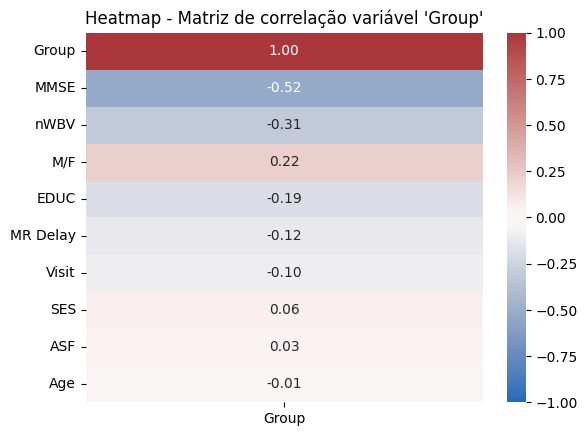

In [ ]:
matriz_correlacao = df.corr(numeric_only=True)[["Group"]].sort_values(by="Group", key=abs, ascending=False)
sns.heatmap(matriz_correlacao, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Heatmap - Matriz de correlação variável 'Group'")
plt.show()

#### Verificação de balanceamento

* Observa-se que o balanceamento do target é muito equilibrado, com menos de 1% de diferença entre eles.
* Acompanhando as tendências do gráfico de correlação, MMSE e nWBV são as variáveis que possivelmente irão influenciar mais no modelo

In [ ]:
balanceamento = df["Group"].value_counts().to_frame()
balanceamento['proporcao'] = df["Group"].value_counts(normalize=True) * 100
balanceamento

,count,proporcao
Group,,
0,190,50.938338
1,183,49.061662


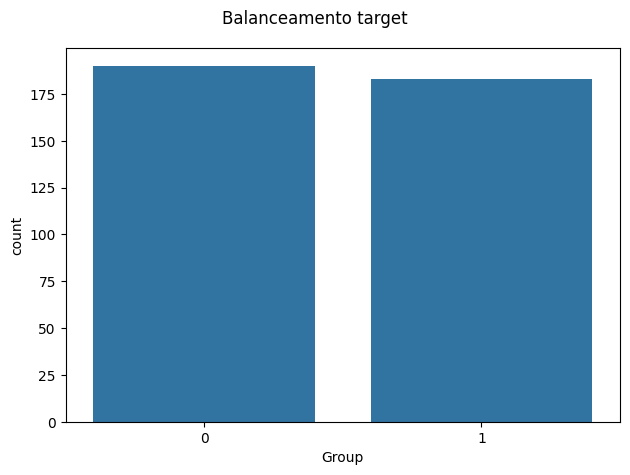

<Figure size 800x600 with 0 Axes>

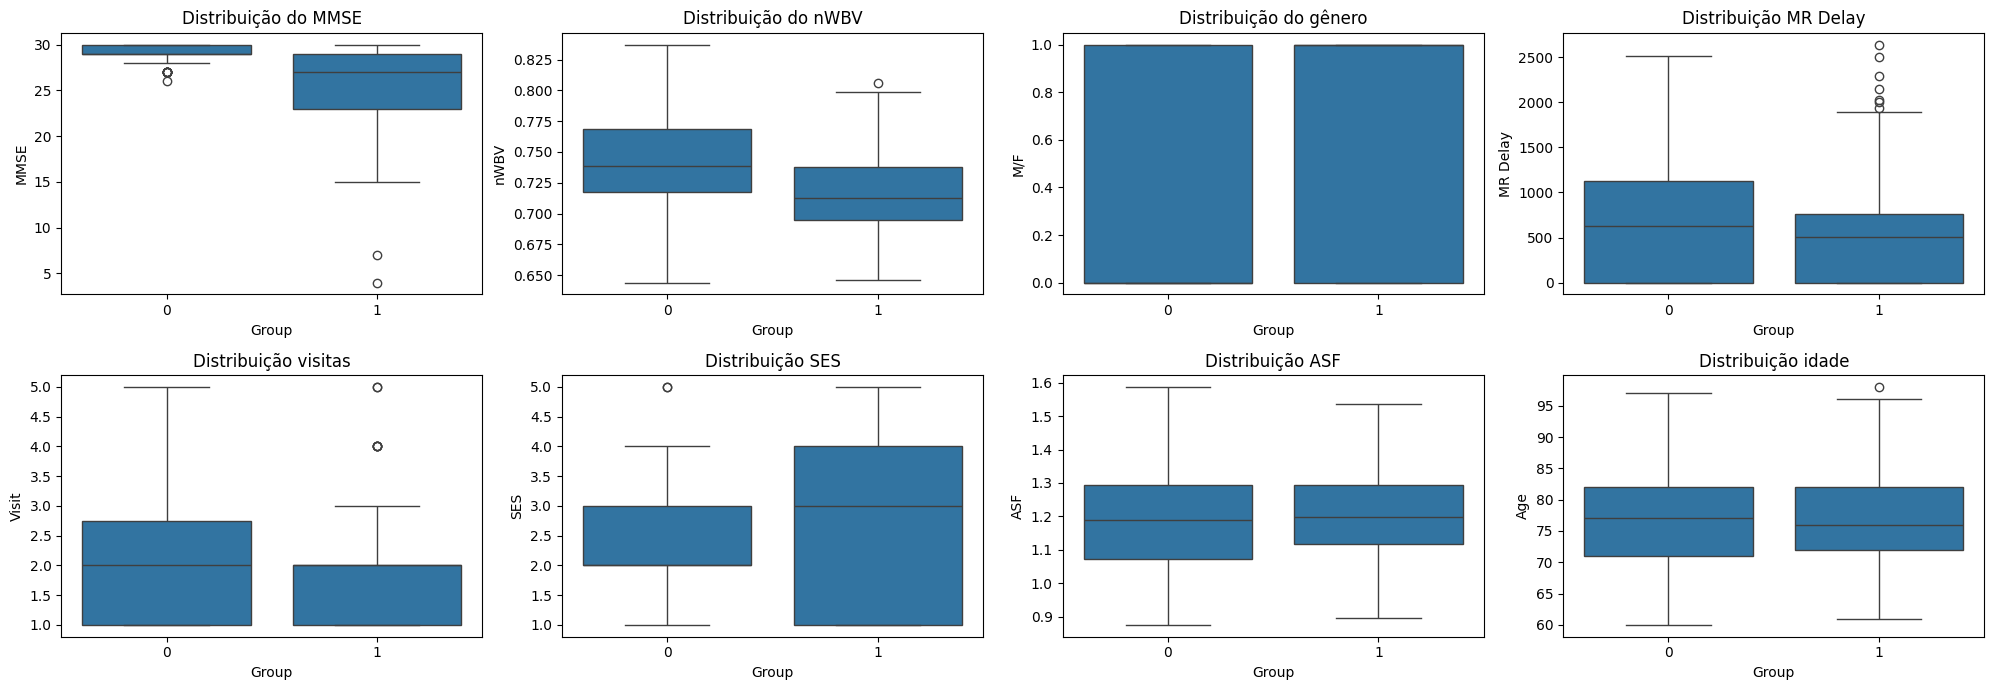

In [ ]:
# Group
sns.countplot(x="Group", data=df)

plt.suptitle("Balanceamento target")
plt.tight_layout()
plt.show()

# Define o tamanho da figura
plt.figure(figsize=(8, 6))


fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 7))

# Plota o boxplot comparando as variáveis entre as classes

sns.boxplot(x="Group", y="MMSE", data=df, ax=axes[0,0])
axes[0,0].set_title("Distribuição do MMSE")

sns.boxplot(x="Group", y="nWBV", data=df, ax=axes[0,1])
axes[0,1].set_title("Distribuição do nWBV")

sns.boxplot(x="Group", y="M/F", data=df, ax=axes[0,2])
axes[0,2].set_title("Distribuição do gênero")

sns.boxplot(x="Group", y="MR Delay", data=df, ax=axes[0,3])
axes[0,3].set_title("Distribuição MR Delay")

sns.boxplot(x="Group", y="Visit", data=df, ax=axes[1,0])
axes[1,0].set_title("Distribuição visitas")

sns.boxplot(x="Group", y="SES", data=df, ax=axes[1,1])
axes[1,1].set_title("Distribuição SES")

sns.boxplot(x="Group", y="ASF", data=df, ax=axes[1,2])
axes[1,2].set_title("Distribuição ASF")

sns.boxplot(x="Group", y="Age", data=df, ax=axes[1,3])
axes[1,3].set_title("Distribuição idade")


plt.tight_layout()
plt.show()


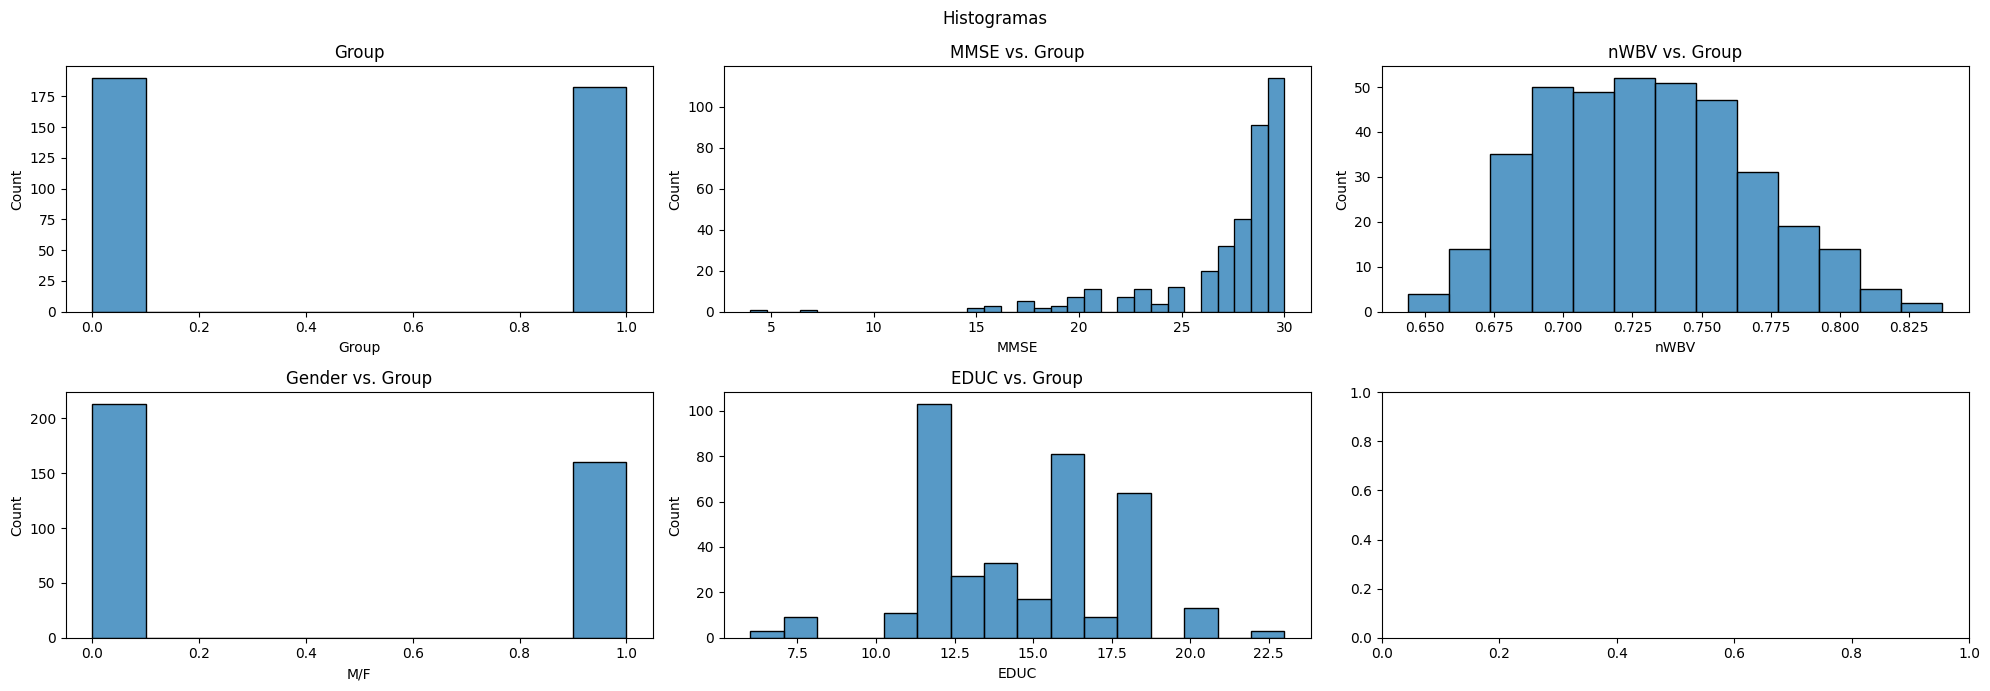

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(20, 7))

# Group
sns.histplot(x="Group", data=df, ax=axes[0, 0])
axes[0, 0].set_title("Group")

# MMSE
sns.histplot(x="MMSE", data=df,  ax=axes[0, 1])
axes[0, 1].set_title("MMSE vs. Group")

# nWBV
sns.histplot(x="nWBV", data=df,  ax=axes[0, 2])
axes[0, 2].set_title("nWBV vs. Group")

# Gender
sns.histplot(x="M/F", data=df, ax=axes[1, 0])
axes[1, 0].set_title("Gender vs. Group")

# EDUC
sns.histplot(x="EDUC", data=df,  ax=axes[1, 1])
axes[1, 1].set_title("EDUC vs. Group")

plt.suptitle("Histogramas")
plt.tight_layout()
plt.show()



---



#### Treinamento de modelo

2. Treine um modelo de classificação (Regressão Logística, Árvore de
Decisão ou Random Forest).

In [ ]:
#Definição das Features (X), Target (y) e Grupos
df_modelo = df.copy()
X = df_modelo.drop(columns=['Group'])
y = df_modelo['Group']
groups = df_modelo['Subject ID']

In [ ]:
#Divisão Treino/Teste Agrupada por Paciente (80% treino, 20% teste)
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

#Remover 'Subject ID' das variáveis preditoras finais
X_train_features = X_train.drop(columns=['Subject ID'])
X_test_features = X_test.drop(columns=['Subject ID'])

Tratamento dos grupos

In [ ]:
#Imputação de nulos (fit APENAS no treino)
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train_features)
X_test_imputed = imputer.transform(X_test_features)

In [ ]:
#Escalamento / Padronização (fit APENAS no treino)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

In [ ]:
#Converter de volta para DataFrame
features = X_train_features.columns
X_train_ready = pd.DataFrame(X_train_scaled, columns=features)
X_test_ready = pd.DataFrame(X_test_scaled, columns=features)

Resultado da divisão dos grupos

In [ ]:
print("VERIFICAÇÃO GERAL (DIMENSÕES E PACIENTES ÚNICOS)")

# Quantidade de registros (linhas, colunas)
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}\n")

# Quantidade de pacientes únicos em cada base
train_subjects = set(X_train['Subject ID'])
test_subjects = set(X_test['Subject ID'])

print(f"Pacientes no Treino: {len(train_subjects)}")
print(f"Pacientes no Teste:  {len(test_subjects)}")

# Confirmação de isolamento (deve retornar set() / 0)
sobreposicao = train_subjects.intersection(test_subjects)
print(f"Pacientes em ambos (deve ser 0): {len(sobreposicao)}")

VERIFICAÇÃO GERAL (DIMENSÕES E PACIENTES ÚNICOS)
X_train shape: (297, 10)
X_test shape:  (76, 10)

Pacientes no Treino: 120
Pacientes no Teste:  30
Pacientes em ambos (deve ser 0): 0


In [ ]:
print("DISTRIBUIÇÃO DA VARIÁVEL TARGET")

# Proporção em % no Treino
print("--- Proporção no TREINO ---")
print(y_train.value_counts(normalize=True).round(3) * 100)

# Proporção em % no Teste
print("\n--- Proporção no TESTE ---")
print(y_test.value_counts(normalize=True).round(3) * 100)

DISTRIBUIÇÃO DA VARIÁVEL TARGET
--- Proporção no TREINO ---
Group
1    51.9
0    48.1
Name: proportion, dtype: float64

--- Proporção no TESTE ---
Group
0    61.8
1    38.2
Name: proportion, dtype: float64


In [ ]:
#visualização da matriz de treino
X_train_ready.head()

,Visit,MR Delay,M/F,Age,EDUC,SES,MMSE,nWBV,ASF
0,-0.961381,-0.935672,1.223028,1.347402,-0.283021,-0.38038,-0.069804,-0.897610,-2.287921
1,0.149631,-0.207686,1.223028,1.477795,-0.283021,-0.38038,0.707638,-1.307665,-2.339212
2,-0.961381,-0.935672,1.223028,-0.217323,-1.001460,-0.38038,-1.106393,0.195869,-1.093557
3,0.149631,-0.043611,1.223028,-0.086929,-1.001460,-0.38038,0.189343,-0.432882,-1.357343
4,1.260644,2.082999,1.223028,0.434646,-1.001460,-0.38038,-1.365541,-0.760926,-1.181485


Testando e Avaliando Modelos

1. Regressão Logística

In [ ]:
# 1. Instanciar e treinar o modelo de Regressão Logística
model_lr = LogisticRegression(random_state=42)
model_lr.fit(X_train_scaled, y_train)

# 2. Fazer as predições no conjunto de teste
y_pred_lr = model_lr.predict(X_test_scaled)

In [ ]:
# 3. Avaliar as métricas solicitadas
print("=== AVALIAÇÃO: REGRESSÃO LOGÍSTICA ===")
print("\nMatriz de Confusão:")
print(confusion_matrix(y_test, y_pred_lr))

print(f"\nAcurácia:  {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precisão:  {precision_score(y_test, y_pred_lr):.4f}")
print(f"Revocação: {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_lr):.4f}")

=== AVALIAÇÃO: REGRESSÃO LOGÍSTICA ===

Matriz de Confusão:
[[30 17]
 [ 9 20]]

Acurácia:  0.6579
Precisão:  0.5405
Revocação: 0.6897
F1-Score:  0.6061


2. Árvore de Decisão

In [ ]:
# 1. Instanciar e treinar o modelo de Árvore de Decisão
model_dt = DecisionTreeClassifier(random_state=42)
model_dt.fit(X_train_imputed, y_train)

# 2. Fazer as predições no conjunto de teste
y_pred_dt = model_dt.predict(X_test_imputed)

In [ ]:
# 3. Avaliar as métricas solicitadas
print("=== AVALIAÇÃO: ÁRVORE DE DECISÃO ===")
print("\nMatriz de Confusão:")
print(confusion_matrix(y_test, y_pred_dt))

print(f"\nAcurácia:  {accuracy_score(y_test, y_pred_dt):.4f}")
print(f"Precisão:  {precision_score(y_test, y_pred_dt):.4f}")
print(f"Revocação: {recall_score(y_test, y_pred_dt):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_dt):.4f}")

=== AVALIAÇÃO: ÁRVORE DE DECISÃO ===

Matriz de Confusão:
[[26 21]
 [ 6 23]]

Acurácia:  0.6447
Precisão:  0.5227
Revocação: 0.7931
F1-Score:  0.6301


3. Random Forest

In [ ]:
# 1. Instanciar e treinar o modelo Random Forest
model_rf = RandomForestClassifier(random_state=42)
model_rf.fit(X_train_imputed, y_train)

# 2. Fazer as predições no conjunto de teste
y_pred_rf = model_rf.predict(X_test_imputed)

In [ ]:
# 3. Avaliar as métricas solicitadas
print("=== AVALIAÇÃO: RANDOM FOREST ===")
print("\nMatriz de Confusão:")
print(confusion_matrix(y_test, y_pred_rf))

print(f"\nAcurácia:  {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precisão:  {precision_score(y_test, y_pred_rf):.4f}")
print(f"Revocação: {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_rf):.4f}")

=== AVALIAÇÃO: RANDOM FOREST ===

Matriz de Confusão:
[[25 22]
 [ 9 20]]

Acurácia:  0.5921
Precisão:  0.4762
Revocação: 0.6897
F1-Score:  0.5634


Análise Crítica dos Resultados
* Desempenho Geral: Sem a variável CDR (que removemos para evitar data leakage), o problema de predição torna-se bastante desafiador. A Regressão Logística obteve o melhor equilíbrio geral (Acurácia de 65,79% e F1-Score de 60,61%).

* Contexto Médico: Em diagnósticos médicos, a Revocação (Recall) costuma ser a métrica mais crítica, pois perder um diagnóstico positivo (Falso Negativo) é mais prejudicial do que solicitar exames adicionais para um Falso Positivo. Sob esse prisma, a Árvore de Decisão capturou a maior proporção de pacientes com demência (72,41%), errando apenas 8 casos.

* Overfitting nas Árvores: O Random Forest sem ajuste de hiperparâmetros (tuning) acabou performando abaixo da Regressão Logística, o que sugere um possível overfitting aos dados de treino devido ao tamanho reduzido da base.

4. Qual a importância relativa de cada variável no modelo final?

A importância varia conforme a natureza do algoritmo:
* MMSE (Mini-Exame do Estado Mental) é, com folga, a variável mais importante em todos os modelos:
  * Regressão Logística: Coeficiente de $-2.97$ (quanto menor a pontuação no MMSE, exponencialmente maior a chance do diagnóstico de demência).
  * Árvore de Decisão: Respondeu por $42.9\%$ do peso das decisões do modelo.
  * Random Forest: Respondeu por $30.4\%$ da importância total.
* Volume Cerebral (nWBV / ASF): É o segundo fator mais relevante. O ASF representa ~$23.2\%$ na Árvore e $15.1\%$ no Random Forest, enquanto o nWBV (volume de massa cinzenta/branca) representa ~$14.0\%$ no Random Forest.
* Variáveis Demográficas (EDUC, Sex, Age): Possuem peso intermediário. Na Regressão Logística, EDUC (anos de estudo) tem efeito protetivo significativo (coeficiente $-0.94$).
* Tempo / Visitas (Visit, MR Delay): Apresentaram a menor importância relativa em todos os modelos ($< 6\%$).

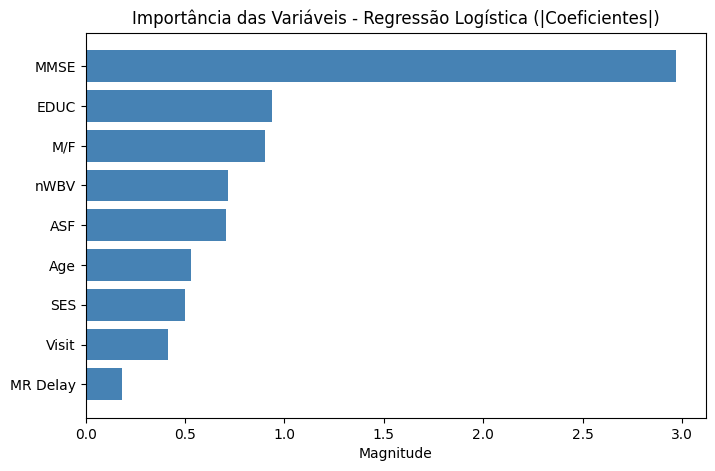

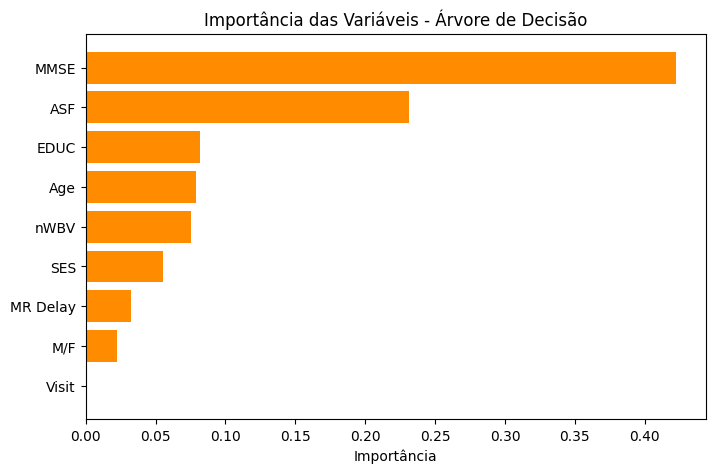

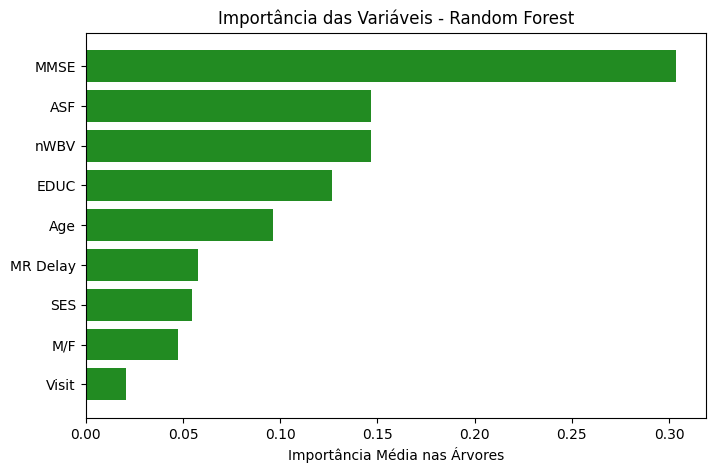

In [ ]:
colunas = X_train_ready.columns

# ==========================================
# 1. REGRESSÃO LOGÍSTICA (Coeficientes)
# ==========================================
# Usamos o valor absoluto dos coeficientes para medir a magnitude do impacto
df_lr = pd.DataFrame({
    'Variavel': colunas,
    'Importancia': abs(model_lr.coef_[0])
}).sort_values(by='Importancia', ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(df_lr['Variavel'], df_lr['Importancia'], color='steelblue')
plt.title('Importância das Variáveis - Regressão Logística (|Coeficientes|)')
plt.xlabel('Magnitude')
plt.show()


# ==========================================
# 2. ÁRVORE DE DECISÃO (.feature_importances_)
# ==========================================
df_dt = pd.DataFrame({
    'Variavel': colunas,
    'Importancia': model_dt.feature_importances_
}).sort_values(by='Importancia', ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(df_dt['Variavel'], df_dt['Importancia'], color='darkorange')
plt.title('Importância das Variáveis - Árvore de Decisão')
plt.xlabel('Importância')
plt.show()


# ==========================================
# 3. RANDOM FOREST (.feature_importances_)
# ==========================================
df_rf = pd.DataFrame({
    'Variavel': colunas,
    'Importancia': model_rf.feature_importances_
}).sort_values(by='Importancia', ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(df_rf['Variavel'], df_rf['Importancia'], color='forestgreen')
plt.title('Importância das Variáveis - Random Forest')
plt.xlabel('Importância Média nas Árvores')
plt.show()

5. O modelo apresenta bom desempenho em ambos os grupos (com e
sem demência)?

Não totalmente. Há uma assimetria importante no desempenho:
* Grupo Sem Demência (Nondemented - 0):Apresenta alta precisão ($71\%$ a $77\%$), mas baixo recall ($53\%$ a $64\%$). Isso significa que, quando o modelo diz que um paciente é saudável, ele costuma acertar, mas ele acaba classificando erroneamente muitos pacientes saudáveis como demenciados (falsos positivos).
* Grupo Com Demência (Demented - 1):Apresenta bom recall ($66\%$ a $72\%$), mas baixa precisão ($46\%$ a $54\%$). O modelo consegue capturar a maioria dos doentes, mas gera um volume alto de falsos alarmes.

6. É possível identificar pacientes em estágio inicial de demência com
esse modelo?

Atualmente, é muito difícil. Analisando especificamente os 12 pacientes do grupo Converted no conjunto de teste (pacientes que entraram no estudo cognitivamente normais e desenvolveram demência nas visitas seguintes):
* Regressão Logística: Acertou apenas $25.0\%$ dos casos.
* Árvore de Decisão: Acertou apenas $33.3\%$ dos casos.
* Random Forest: Acertou apenas $16.7\%$ dos casos.

Por que isso acontece? Pacientes em fase de transição inicial ainda possuem pontuações de MMSE e volumes cerebrais (nWBV) muito próximos de pessoas saudáveis. Como removemos a variável CDR (que indicaria o estágio diretamente) e não criamos variáveis de tendência/evolução temporal (ex: variação de MMSE entre a Visita 1 e Visita 2), o modelo estático falha em detectar o estágio inicial.

7. O modelo apresenta overfitting ou underfitting? Como isso pode ser
ajustado?

Todos os modelos apresentam underfitting, contando com acurácia abaixo de 65%. O ajuste do modelo pode ser feito de diversas maneiras. Os principais são:

*   **Ajuste de hiperparâmetros** através do uso de variáveis com  números diversos, aprimorados progressivamente a cada melhora do modelo
* **Aplicação de modelos mais robustos** pode auxiliar em uma melhor leitura desse dataset
* **Criação de variáveis (feature engeneering)** pela combinação de variáveis expressas no dataset
* **Estudo mais aprofundado das variáveis no contexto médico** ajudaria a ter uma compreensão mais complexa de como cada uma impacta no modelo em contextos reais

O balanceamento das classes poderia ser uma alternativa, mas o presente dataset aparenta ter um bom balanceamento de classes target.

## **Conclusões**

<img src='https://github.com/squad-ada-lovelace/Desafio_06-Classificacao/blob/main/assets/6.png?raw=true'>

## **Facilidades e dificuldades**

<img src='https://github.com/squad-ada-lovelace/Desafio_06-Classificacao/blob/main/assets/7.png?raw=true'>